Script to automatically align volumetric scape data to a muscle reference map by using the accessory heart muscles.

Requires first manually labelled the accessory heart muscles in the scape video. Note: do this when the muscle is lit up but not when it is contracted, as it distorts its shape.

Steps:
- Load manual rois 
- Load max projection for matching data
- asign manual rois an identity (RF, LF, etc.) - remember right is on left when looking at legs
- Load reference labels (for acc-heart-muscles but also all selected muscles)
- get centroid of both manual and referece
- scale, rotate and shift reference to match manual - how does it look? Compare selected muscles to max projection
- if not great, try stretching

### Load all relevant data

In [22]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import distance

from scape_utils import load_napari_rois, load_voxel_size, load_aspect_ratio_YX, load_proj

import sys
sys.path.append(str(Path('/home/azcorra/git/Devel/Pupa_muscle_imaging/referenceMaps')))
from webknossos import load_labels

In [23]:
# set paths to data and reference map labels:
main_path = Path('/mnt/labserver/data/MA/SCAPE/')
scape_path = main_path / '20260716_MA12_pupa-P15/sample2_run2'
acc_heart_path = scape_path / 'accessory_heart_muscles_rois.nrrd'

reference_path = Path('/mnt/labserver/data/MA/CT_scans_PIXE/2026-06-16_Webknossos_muscle_leg_tracing_pupa_annotations/Front Right Leg muscles in pupa')
labels_path = reference_path / 'Labels'
selected_path = reference_path / 'meshes-selected'

In [24]:
# Get std image for scape data (and aspect_ratio for plotting)
std = load_proj(scape_path, 'std_image')
voxel_sizes = load_voxel_size(scape_path)
axes_order = list(voxel_sizes.keys())

aspect_ratio = [
    voxel_sizes[others[0]] / voxel_sizes[others[1]]
    for i, element in enumerate(axes_order)
    for others in [axes_order[:i] + axes_order[i+1:]]
]

In [25]:
# Load manual rois for accessory heart muscles (labels)
acc_heart_manual = load_napari_rois(acc_heart_path)
acc_heart_manual_id = {'RM': 1, 'RF': 2, 'LF': 3, 'LM': 4}

In [26]:
# Load reference labels
labels, id_to_name = load_labels(labels_path) # takes about 1 min
# webknossos labels are indexed (x,y,z); reorder to match manual (z,y,x) axes
# (must reverse axis order, not permute (1,2,0) which gives (y,z,x)):
labels = np.transpose(labels, (2, 1, 0))
# two axes are inverted (point reflection) - so reverse
labels = labels[::-1, ::-1, :]

# select accessory heart muscles
acc_heart_ref_id = {name[:2]: id for id, name in id_to_name.items() if 'heart' in name and 'p1' in name}
# find the selected muscles (all files in the selected_path folder)
stl_list = list(selected_path.glob('*.stl'))
selected_muscles = {k: v for k, v in (p.stem.rsplit('-', 1) for p in stl_list)}

### Align centroids

In [27]:
# get centroids for each accessory heart muscle in the reference and manual rois
centroids_manual = {}
centroids_ref = {}

for leg, id in acc_heart_manual_id.items():

    # manual centroids
    mask_manual = acc_heart_manual == id
    coords_manual = np.argwhere(mask_manual)
    centroids_manual[leg] = coords_manual.mean(axis=0)

    # correct manual centroids for aspect ratio
    centroids_manual[leg] = centroids_manual[leg] * list(voxel_sizes[ax] for ax in axes_order)

    # reference centroids
    ref_id = acc_heart_ref_id[leg]
    mask_ref = labels == ref_id
    coords_ref = np.argwhere(mask_ref)
    centroids_ref[leg] = coords_ref.mean(axis=0)

    del mask_manual, coords_manual, mask_ref, coords_ref


### Fit similarity transform

In [28]:
def fit_similarity_transform(source_points, target_points):
    """
    Fits a rigid + uniform scale transform mapping source points onto
    target points, using Umeyama's closed-form least-squares algorithm.

    Solves for the rotation `R`, scale `s`, and translation `t` that
    minimize `sum(||s * R @ source_i + t - target_i||**2)` over all
    corresponding point pairs. Points must already be in correspondence
    (`source_points[i]` matches `target_points[i]`).

    Parameters
    ----------
    source_points : (N, 3) array
        Points to be transformed (here: reference centroids).

    target_points : (N, 3) array
        Points to align to (here: manual centroids, in physical units).

    Returns
    -------
    R : (3, 3) array
        Rotation matrix.

    scale : float
        Uniform scale factor.

    t : (3,) array
        Translation vector.
    """
    source = np.asarray(source_points, dtype=float)
    target = np.asarray(target_points, dtype=float)
    n_points = source.shape[0]

    mean_source = source.mean(axis=0)
    mean_target = target.mean(axis=0)
    source_centered = source - mean_source
    target_centered = target - mean_target

    covariance = (target_centered.T @ source_centered) / n_points
    U, singular_values, Vt = np.linalg.svd(covariance)

    S = np.eye(3)
    if np.linalg.det(U) * np.linalg.det(Vt) < 0:
        S[-1, -1] = -1

    R = U @ S @ Vt
    source_variance = np.sum(source_centered ** 2) / n_points
    scale = np.sum(singular_values * np.diag(S)) / source_variance
    t = mean_target - scale * (R @ mean_source)

    return R, scale, t

In [29]:
def build_homogeneous_transform(R, scale, t):
    """
    Assembles a rotation, scale, and translation into a 4x4 homogeneous
    transform mapping `x` to `scale * R @ x + t`.

    Parameters
    ----------
    R : (3, 3) array
        Rotation matrix.

    scale : float
        Uniform scale factor.

    t : (3,) array
        Translation vector.

    Returns
    -------
    (4, 4) array
        Homogeneous transform matrix.
    """
    T = np.eye(4)
    T[:3, :3] = scale * R
    T[:3, 3] = t
    return T

In [30]:
# fixed correspondence order so the reference/manual point arrays line up
# by leg identity, not by dict iteration order
leg_order = ['RM', 'RF', 'LF', 'LM']
ref_points = np.array([centroids_ref[leg] for leg in leg_order])
manual_points = np.array([centroids_manual[leg] for leg in leg_order])

R, scale, t = fit_similarity_transform(ref_points, manual_points)
T_forward = build_homogeneous_transform(R, scale, t)

ref_points_aligned = {
    leg: scale * (R @ centroids_ref[leg]) + t for leg in leg_order
}
residuals = {
    leg: np.linalg.norm(ref_points_aligned[leg] - centroids_manual[leg])
    for leg in leg_order
}

print(f'Fitted scale (reference voxel units -> manual physical units): {scale:.4f}')
print(f'Per-landmark residual after fit (µm): {residuals}')

for leg_a, leg_b in [('RF', 'LF'), ('RM', 'LM')]:
    dist_manual = np.linalg.norm(centroids_manual[leg_a] - centroids_manual[leg_b])
    dist_aligned = np.linalg.norm(ref_points_aligned[leg_a] - ref_points_aligned[leg_b])
    print(f'{leg_a}-{leg_b} distance (µm) — manual: {dist_manual:.2f}, aligned reference: {dist_aligned:.2f}')

Fitted scale (reference voxel units -> manual physical units): 0.5965
Per-landmark residual after fit (µm): {'RM': np.float64(26.36554239409566), 'RF': np.float64(20.26413898587279), 'LF': np.float64(16.10381821065954), 'LM': np.float64(24.479580369439997)}
RF-LF distance (µm) — manual: 562.00, aligned reference: 567.04
RM-LM distance (µm) — manual: 572.65, aligned reference: 537.81


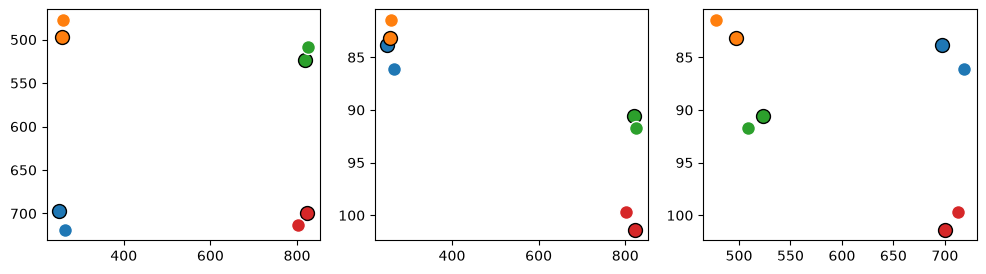

In [31]:
# QC: black-outlined = manual, white-outlined = fitted reference; same
# color = same leg identity. Overlapping same-colored pairs indicate a
# good fit.
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
fig, axs = plt.subplots(1, 3, figsize=[12, 3])
for ax_idx, ax_plot in enumerate(axs):
    axes = [n for n in [0, 1, 2] if n != ax_idx]
    for i, leg in enumerate(leg_order):
        manual_centroid = manual_points[i]
        aligned_centroid = ref_points_aligned[leg]
        ax_plot.plot(manual_centroid[axes[1]], manual_centroid[axes[0]], 'o', ms=10, mec='k', mfc=colors[i])
        ax_plot.plot(aligned_centroid[axes[1]], aligned_centroid[axes[0]], 'o', ms=10, mec='w', mfc=colors[i])
    ax_plot.invert_yaxis()

### Warp reference volume onto manual grid

In [32]:
from scipy.ndimage import affine_transform


def warp_labels_to_manual_grid(source_volume, T_forward, target_shape,
                                source_voxel_size=(1.0, 1.0, 1.0),
                                target_voxel_size=(1.0, 1.0, 1.0)):
    """
    Resamples a labeled voxel volume onto a differently-spaced target grid,
    using a rigid + uniform scale transform fit on physical-space points.

    All coordinates and voxel sizes are in array-axis order (matching
    `source_volume`'s and `target_shape`'s own axis order, e.g. (z, y, x)) —
    since `T_forward` was fit directly on `np.argwhere`-derived centroids in
    that same order, no physical (x, y, z) <-> array-index permutation is
    needed here.

    Parameters
    ----------
    source_volume : ndarray
        Labeled array to resample from (e.g. the reference `labels`
        volume).

    T_forward : (4, 4) array
        Homogeneous transform mapping source physical coordinates to
        target physical coordinates (see `build_homogeneous_transform`).

    target_shape : tuple of int
        Output array shape, matching the target grid (e.g.
        `acc_heart_manual.shape`).

    source_voxel_size : tuple of float
        Physical size per voxel of `source_volume`, one value per axis.

    target_voxel_size : tuple of float
        Physical size per voxel of the output grid, one value per axis.

    Returns
    -------
    ndarray
        `source_volume` resampled onto the target grid, with label IDs
        preserved via nearest-neighbor interpolation.
    """
    S_source = np.diag([*source_voxel_size, 1.0])
    S_target = np.diag([*target_voxel_size, 1.0])

    # maps target voxel indices to source voxel indices (pull mapping,
    # as required by affine_transform)
    T_voxel = np.linalg.inv(S_source) @ np.linalg.inv(T_forward) @ S_target

    return affine_transform(
        source_volume,
        matrix=T_voxel[:3, :3],
        offset=T_voxel[:3, 3],
        output_shape=target_shape,
        order=0,
        mode='constant',
        cval=0,
    )

In [33]:
target_voxel_size = tuple(voxel_sizes[ax] for ax in axes_order)

labels_aligned = warp_labels_to_manual_grid(
    labels, T_forward,
    target_shape=acc_heart_manual.shape,
    source_voxel_size=(1.0, 1.0, 1.0),
    target_voxel_size=target_voxel_size,
)

print('Reference non-zero voxels:', np.count_nonzero(labels))
print('Aligned non-zero voxels:', np.count_nonzero(labels_aligned))
print('Unique labels preserved:', np.unique(labels_aligned))

Reference non-zero voxels: 68353692
Aligned non-zero voxels: 2449557
Unique labels preserved: [ 0  1  2  3  4  5  6  7  8  9 10 11 13 14 15 16 17 18 19 20 21 23 24 25
 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 46 47 48 49 50
 51 52 53 54 55 56 57 58 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75
 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99]


### Visual QC: compare aligned reference to SCAPE data

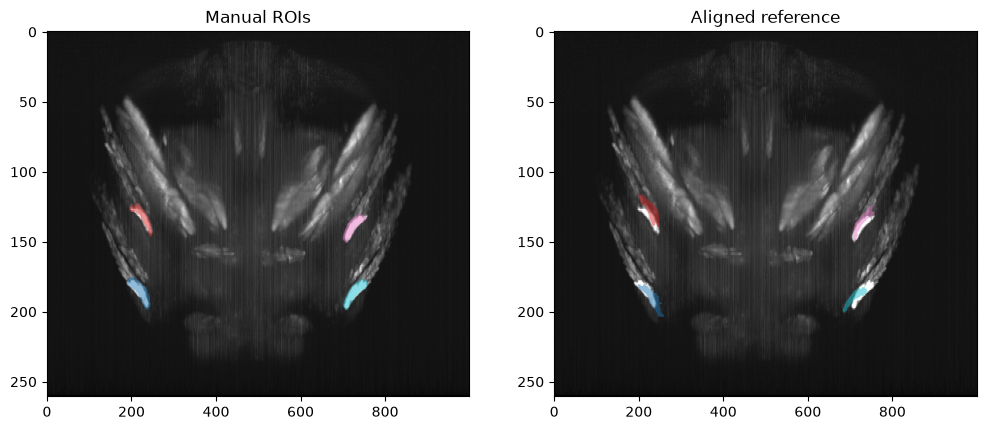

In [40]:
# relabel the aligned reference's heart-muscle IDs to match acc_heart_manual_id,
# so the two overlays share the same color mapping
ax_proj = 0  # project along z, matching how std/acc_heart_manual are viewed above

# std is a 3D per-voxel temporal-std volume, not a precomputed 2D
# projection, so it needs to be projected too before display
std_proj = np.max(std, axis=ax_proj)

acc_heart_aligned = np.zeros_like(labels_aligned, dtype=np.uint8)
for leg, ref_id in acc_heart_ref_id.items():
    acc_heart_aligned[labels_aligned == ref_id] = acc_heart_manual_id[leg]

fig, axs = plt.subplots(1, 2, figsize=[12, 6])
for ax_plot, volume, title in zip(
    axs, (acc_heart_manual, acc_heart_aligned), ('Manual ROIs', 'Aligned reference')
):
    ax_plot.imshow(std_proj, aspect=aspect_ratio[ax_proj], cmap='gray', vmax=80)
    overlay = np.ma.masked_equal(np.max(volume, axis=ax_proj), 0)
    ax_plot.imshow(overlay, aspect=aspect_ratio[ax_proj], cmap='tab10', alpha=0.5, vmin=1, vmax=4)
    ax_plot.set_title(title)

Text(0.5, 1.0, 'All selected muscles, aligned reference')

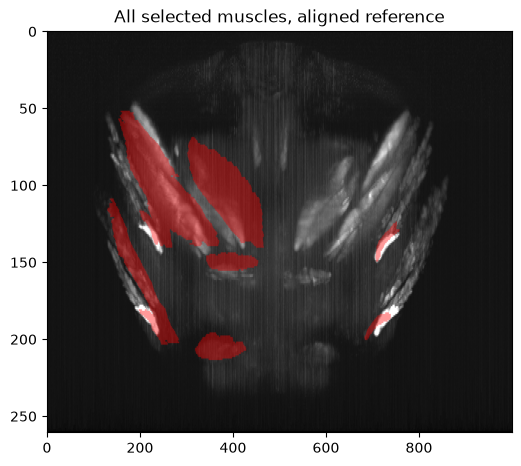

In [41]:
# broader sanity check: do all the selected leg muscles (not just the
# heart-muscle landmarks used to fit the transform) look anatomically
# plausible against the SCAPE std projection?
selected_ids = {int(muscle_id) for muscle_id in selected_muscles.values()}
selected_mask = np.isin(labels_aligned, list(selected_ids))

plt.figure(figsize=[6, 6])
plt.imshow(std_proj, aspect=aspect_ratio[ax_proj], cmap='gray', vmax=80)
overlay = np.ma.masked_equal(np.max(selected_mask, axis=ax_proj), 0)
plt.imshow(overlay, aspect=aspect_ratio[ax_proj], cmap='autumn', alpha=0.4)
plt.title('All selected muscles, aligned reference')

# CONVERTING REFERENCE TO PSEUDO-SCAPE